# 07 · Final cross-experiment results analysis

## 1. Research overview

**How faithfully can LLMs explain XGBoost hospital readmission predictions, and how do SHAP grounding, adversarial attribution patterns, and deterministic verification affect mathematical correctness and human-perceived explanation quality?**

| Experiment | Research objective |
|---|---|
| 1 | Establish the prediction model and SHAP reference |
| 2 | Evaluate LLM explanation faithfulness under A/B/C conditions |
| 3 | Stress-test counterintuitive signed attributions |
| 4 | Quantify verifier detection, false rejection and correction behavior |
| 5 | Assess human-rated faithfulness, clarity and readability |

The study proceeds from an observational prediction model to a matched explanation comparison, fictional stress tests, and a single-reviewer assessment of saved A/B/C deliveries. A receives inputs and predicted risk. B adds signed SHAP information. C checks the exact B draft, allows one Qwen3 revision, and uses a deterministic fallback if release checks still fail.

- **H1 · SHAP grounding.** Supplying case-level attributions improves agreement with the fitted model’s most influential features and their directions.
- **H2 · Deterministic verification.** Checking the grounded draft, requesting a correction, and using a fallback when needed improves the final system’s agreement and completeness.
- **H3.** Qwen3 may explain a fitted model less faithfully when its local contributions conflict with familiar clinical expectations. The primary contrast is counterintuitive minus intuitive signed top-three agreement within profile, separately in A, B and C.
- **H4.** The deterministic verifier will detect explicit structured attribution errors more reliably than mathematical errors embedded in complex prose, and will falsely reject more faithful explanations written in unfamiliar ways.
- **H5a.** B will have higher human-assessed faithfulness than A. The human rubric independently judges C against the saved reference.
- **H5b.** C may have lower readability than B when deterministic fallback introduces repetitive phrasing.
- **H5c.** Faithfulness and readability may improve or decline separately.
- **H5d.** In the optional synthetic study, explanations may remain clinically plausible while disagreeing with a counterintuitive model reference.

Predictive performance is evaluated against observed readmission. Explanation faithfulness is evaluated against the fitted model. Signed SHAP decomposes its raw log-odds relative to a reference. Clinical plausibility, causal effects and clinical decision-making efficacy are distinct from either endpoint.

## 2. Frozen source validation

Open with the HRP Python kernel. Choose `review` for local, read-only synthesis, `validate` for source and existing-output integrity, `export` to create an immutable public aggregate version, or `fictional` for a scripted software fixture. Keep executed local aggregate outputs in the authorized environment and clear outputs before sharing this notebook.

Each study retains its original unit of analysis and denominators. Some admissions and explanations recur across stages. The authored fictional challenges target different behaviors and have a different sampling design. Pooling would confound these endpoints and count some evidence twice.

In [1]:
from pathlib import Path
import sys

sys.dont_write_bytecode = True
src = next(p for p in (Path.cwd(), Path.cwd() / "src") if (p / "results_synthesis.py").is_file())
if str(src) not in sys.path:
    sys.path.insert(0, str(src))

import pandas as pd
from IPython.display import Image, Markdown, display
from results_synthesis import (
    CLEAR, FAITH, READ, SIGNED, Sources, hypothesis_rows, human_comparison_rows,
    human_condition_rows, human_verifier_rows, paired_grounding, paired_reversal,
    run, verifier_metrics, verifier_rows,
)
from results_synthesis_figures import (
    captions, fictional_figure, figure_bytes, grounding_figure, pipeline_figure, release_figure,
)

MODE = "review"
HUMAN_VERSION = "results-v1"
PRIVATE_HUMAN_DIRECTORY = None  # Defaults to the owner-only Experiment 5 directory.
EXPORT_VERSION = "v1"

source_options = {"human_version": HUMAN_VERSION}
if PRIVATE_HUMAN_DIRECTORY is not None:
    source_options["human_directory"] = Path(PRIVATE_HUMAN_DIRECTORY)
study = run(MODE, sources=Sources(**source_options), version=EXPORT_VERSION)
analyses = {} if MODE == "validate" or study.fictional else study.data

def table(rows, columns=None):
    frame = pd.DataFrame(rows)
    display((frame if columns is None else frame[columns]).round(4))

def figure(name, data=None):
    display(Image(data=study.images[name] if data is None else data))
    display(Markdown(captions(study)[name]))

if study.fictional:
    display(Markdown("**Scripted fictional ratings for software validation.**"))
    table(human_condition_rows(study.data[5]))
    display(Image(data=figure_bytes(fictional_figure(study))))
else:
    table([dict(experiment=r["experiment"], dataset=r["dataset"], n=r.get("observations"),
                records=r.get("records"), unit=r["unit"], analysis=r.get("analysis"),
                checksum=next(iter(r.get("artifacts", {}).values()), None),
                status=r["status"], diagnostic=r.get("diagnostic")) for r in study.provenance])
    if MODE == "validate":
        print("Validated all five sources." if study.validated else "See the source diagnostics above.")

/Users/sghosh/Documents/Github/AI380H/HRP/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,experiment,dataset,n,records,unit,analysis,checksum,status,diagnostic
0,1,MIMIC-IV v3.1,358194,NaN,admission (patient-clustered test uncertainty),frozen model evaluation v1,072840d4f1b0ea5a3d3b26311de8a9d275d92751d16552...,validated,None
1,2,MIMIC-IV v3.1 risk-stratified sample,72,216.0,matched admission,experiment2-analysis-v1,42038ff9ceef439a3bb8797b419869ed7638610173c36e...,validated,None
2,3,Fictional attribution reversals,48,288.0,matched fictional profile,experiment3-analysis-v2,8b264b5e2c9aa0ca97ca8f5a7b078d82078ac04c78ca84...,validated,None
3,4,Fictional verifier challenge,180,180.0,challenge response (profile-clustered),experiment4-analysis-v1,c20b925e563d7a6479e9e2daf0cfca0518c0c0d8c4610a...,validated,None
4,5,MIMIC-IV v3.1 selected triplets,24,72.0,matched admission,experiment5-analysis-v1,70d20de896ec71359ff666315359882fd9efe7a342f0bb...,validated,None


## 3. Experiment 1 · Prediction model and SHAP reference

The patient-disjoint validation partition selected XGBoost and fixed its decision threshold. Test performance is the held-out estimate. Average precision summarizes the precision–recall curve and is shown with prevalence as the no-skill reference. The candidate sigmoid was evaluated on validation. Subsequent experiments use the saved final probability and grouped raw-margin SHAP values. The training partition supplied the fitting and SHAP background data.

,partition,patients,admissions,readmissions,readmission_pct
0,train,122672,251031,28060,11.1779
1,validation,26287,53784,6156,11.4458
2,test,26287,53379,5989,11.2198


,split,model,n,probability_source,threshold,roc_auc,average_precision,prevalence,brier,mean_probability,precision,recall,f1,roc_auc_ci95,average_precision_ci95
0,validation,logistic,53784,raw,0.1641,0.7252,0.2649,0.1145,0.0936,0.1128,NaN,NaN,NaN,None,None
1,validation,xgboost,53784,raw,0.1960,0.7559,0.3210,0.1145,0.0900,0.1130,NaN,NaN,NaN,None,None
2,test,logistic,53379,raw,0.1641,0.7221,0.2540,0.1122,0.0925,0.1114,0.2551,0.4547,0.3268,"[0.7126724836628879, 0.7304229417654091]","[0.23865317300027075, 0.2726566845785042]"
3,test,xgboost,53379,raw,0.1960,0.7554,0.3038,0.1122,0.0892,0.1118,0.3051,0.4113,0.3503,"[0.7468875528890515, 0.7637551069571922]","[0.2823607565712563, 0.32795965304290803]"


,calibration,roc_auc,average_precision,brier,mean_probability,prevalence
0,raw,0.7559,0.321,0.0900,0.1130,0.1145
1,sigmoid_oof,0.7558,0.321,0.0899,0.1144,0.1145


XGBoost met the validation AP, probability quality, and fold consistency criteria. CPU histogram training and TreeExplainer support the explanation workflow.


,feature,mean_abs_shap
0,admission_type,0.3461
1,days_since_previous_discharge,0.2713
2,admission_location,0.2321
3,prior_admissions,0.1732
4,hemoglobin,0.1412
5,bun,0.0862
6,platelets,0.0690
7,sodium,0.0630
8,sodium_missing,0.0561
9,glucose,0.0407


,rows,max_abs_error,mean_expected_value
0,1000,0.0,-2.3958


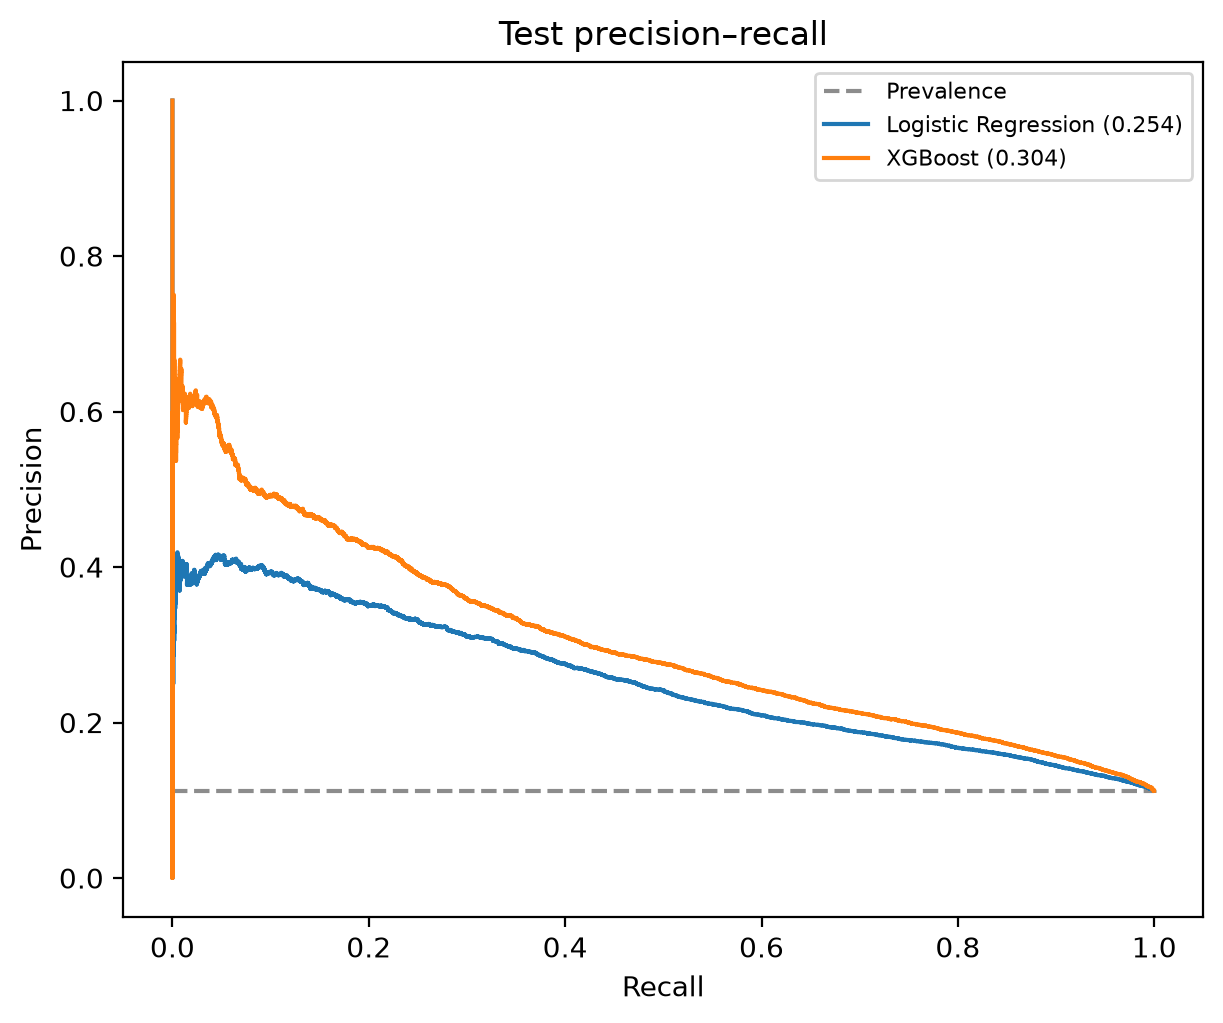

Experiment 1 · frozen model evaluation v1. Held-out test set, n=53,379 admissions. The horizontal line marks prevalence. Patient-cluster intervals for average precision are in the performance table.

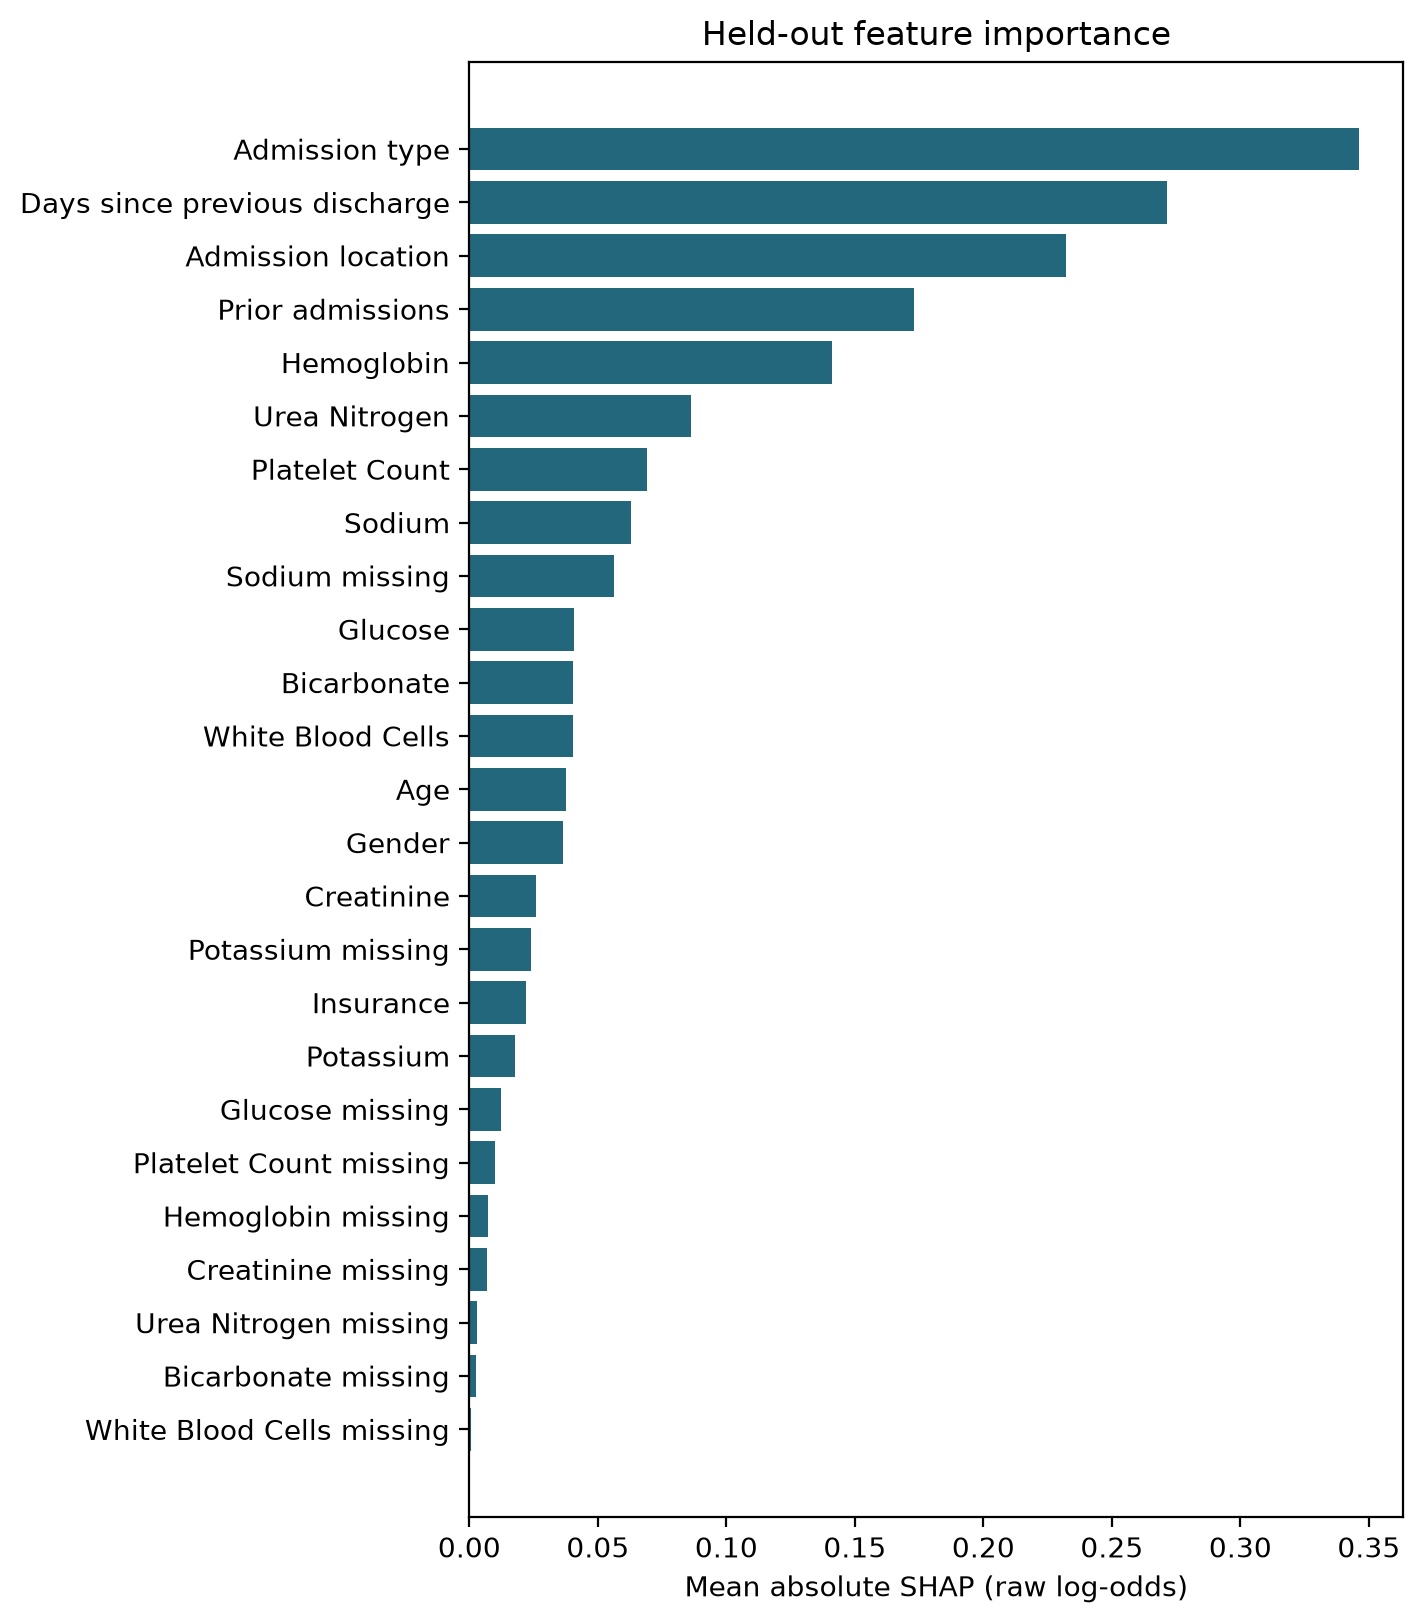

Experiment 1 · frozen model evaluation v1. Mean absolute grouped SHAP contribution in raw log-odds across 1,000 test admissions. Descriptive feature importance.

In [2]:
if 1 in analyses:
    e1 = analyses[1]
    table(e1["partitions"])
    table(e1["performance"])
    table([{"calibration": label, **e1["xgboost_calibration"][label]}
           for label in ("raw", "sigmoid_oof")])
    print(e1["selected"]["rationale"])
    table(e1["importance"])
    table([e1["shap_diagnostics"]])
    figure("01_test_precision_recall")
    figure("02_global_shap")

## 4. Experiment 2 · SHAP-grounded explanation faithfulness

Signed agreement counts up to three matching feature–direction pairs. Overlap ignores direction. Missing drivers and direction errors describe structured responses. Narrative counts reflect clauses recognized by the frozen parser, whose inability to parse a sentence leaves its meaning unresolved. C is a continuation of B on the same draft. The revision and fallback counts describe how C was delivered, while call latency measures inference work.

The selected Experiment 2 export is analysis v1. The read-only v2 analysis reproduces its quantitative summary and CSV tables. The saved values below therefore retain the original version and intervals.

,condition,valid,total,top_three_overlap,signed_top_three_agreement,rank_position_agreement,exact_top_three_ordering,missing_influential_drivers,incorrect_feature_directions,structured_correct,structured_complete
0,A,70,72,1.3429,1.0000,0.3857,0.0143,1.6571,0.7143,0.0714,0.0429
1,B,72,72,2.9444,2.9167,2.7222,0.8750,0.0556,0.0278,0.8611,0.9583
2,C,72,72,3.0000,3.0000,3.0000,1.0000,0.0000,0.0000,1.0000,1.0000


,condition,valid,verified_directional_clauses,incorrect_directional_clauses,unsupported_claim_clauses,contradicted_clauses,checked_clauses,unparsed_clauses,descriptive_clauses,missing_top_three_directions,complete_prose_outputs,parser_coverage,prose_completeness
0,A,70,0,0,1,1,1,209,68,210,0,0.0048,0.0
1,B,72,13,0,2,2,15,179,62,203,0,0.0773,0.0
2,C,72,216,0,0,0,216,0,72,0,72,1.0000,1.0


,rejected,structured_correct,structured_correct_and_ambiguous,responses_with_contradictions
0,72,62,62,2


,outcome,count
0,draft_accepted,0
1,revision_requested,72
2,revision_accepted,8
3,revision_rejected,64
4,fallback_used,64
5,verified_complete,72


,stage,calls,seconds,mean_seconds,median_seconds
0,A,72,802.7466,11.1493,9.7455
1,B,72,1132.5694,15.7301,15.5273
2,C,72,589.3305,8.1851,7.9023
3,C delivery (B + C),144,1721.8999,11.9576,13.0602
4,Total unique,216,2524.6465,11.6882,9.8621


,comparison,analysis,metric,pairs,observed_valid_pairs,excluded_pairs,mean_difference,ci95_low,ci95_high
0,A→B,complete_case,top_three_overlap,70,70,2,1.6000,1.4286,1.7714
1,A→B,complete_case,signed_top_three_agreement,70,70,2,1.9429,1.7571,2.1286
2,A→B,complete_case,rank_position_agreement,70,70,2,2.3286,2.1000,2.5429
3,A→B,complete_case,exact_top_three_ordering,70,70,2,0.8571,0.7714,0.9286
4,A→B,failure_inclusive,top_three_overlap,72,70,0,1.6389,1.4583,1.8056
5,A→B,failure_inclusive,signed_top_three_agreement,72,70,0,1.9444,1.7639,2.1250
6,A→B,failure_inclusive,rank_position_agreement,72,70,0,2.3472,2.1250,2.5556
7,A→B,failure_inclusive,exact_top_three_ordering,72,70,0,0.8611,0.7778,0.9306
8,B→C,complete_case,top_three_overlap,72,72,0,0.0556,0.0000,0.1250
9,B→C,complete_case,signed_top_three_agreement,72,72,0,0.0833,0.0139,0.1806


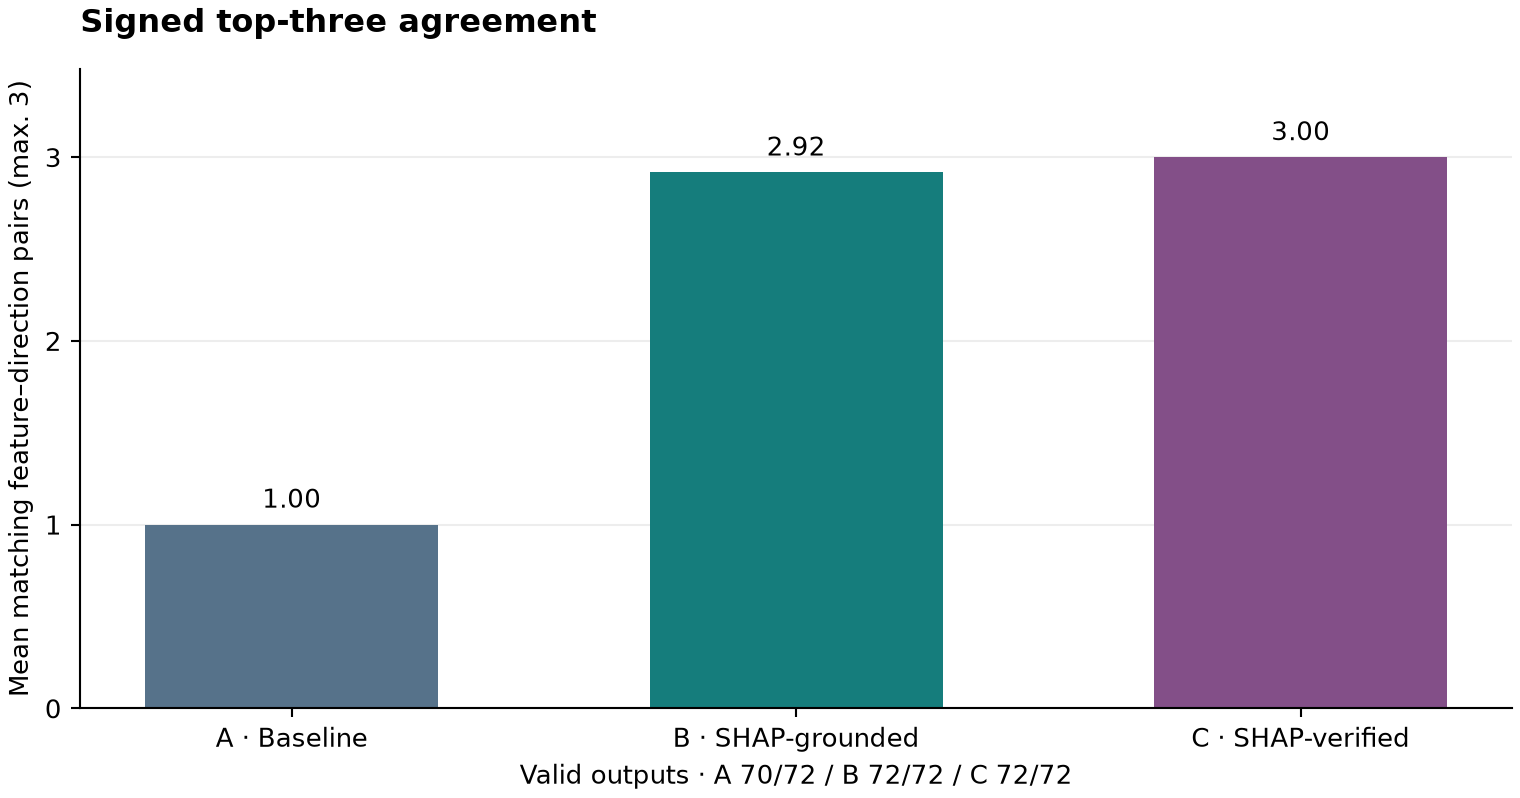

Experiment 2 · experiment2-analysis-v1. Descriptive means among valid explanations (A 70/72, B 72/72, C 72/72). See the matched comparison table for 95% bootstrap intervals.

In [3]:
if 2 in analyses:
    e2 = analyses[2]
    table(e2["structured"])
    table(e2["narrative"])
    table([e2["grounded_audit"]])
    table(e2["interventions"])
    table(e2["costs"])
    table(e2["paired"])
    figure("03_grounding_agreement", figure_bytes(grounding_figure(e2)))

## 5. Experiment 3 · Adversarial faithfulness

Each authored fictional profile is evaluated with intuitive and counterintuitive model variants. Structured substitution means a reported driver follows the authored clinical expectation where the reference reverses it. The prose-inclusive classification depends on parser coverage. Negative paired differences indicate worse performance under reversal. The alternate model can also change predicted risk, so the contrast combines the sign change with any accompanying probability change. These are controlled benchmark frequencies.

,condition,variant,total,valid,signed_top_three_agreement,structured_correct,incorrect_direction_rate,incorrect_prose_direction_rate,parser_coverage
0,A,intuitive,48,44,1.6591,0.0000,0.4773,0,0.0000
1,A,counterintuitive,48,46,0.6522,0.0000,1.0000,0,0.0159
2,B,intuitive,48,48,2.9583,0.7708,0.0000,0,0.0000
3,B,counterintuitive,48,48,2.7292,0.8750,0.1250,0,0.0000
4,C,intuitive,48,48,3.0000,1.0000,0.0000,0,1.0000
5,C,counterintuitive,48,48,3.0000,1.0000,0.0000,0,1.0000


,stratum,condition,metric,policy,pairs,selected_pairs,mean_difference,ci95_low,ci95_high
0,all,A,signed_top_three_agreement,valid_pairs,44,48,-1.0000,-1.2273,-0.7619
1,all,A,signed_top_three_agreement,failed_outputs_zero,48,48,-0.8958,-1.1250,-0.6667
2,all,B,signed_top_three_agreement,valid_pairs,48,48,-0.2292,-0.4792,-0.0208
3,all,B,signed_top_three_agreement,failed_outputs_zero,48,48,-0.2292,-0.4792,-0.0208
4,all,C,signed_top_three_agreement,valid_pairs,48,48,0.0000,0.0000,0.0000
5,all,C,signed_top_three_agreement,failed_outputs_zero,48,48,0.0000,0.0000,0.0000


,layer,condition,variant,top_three_only,outcome,count,denominator,rate
0,Structured,A,intuitive,False,clinical_expectation_substitution,0,96,0.0000
1,Structured,A,counterintuitive,False,clinical_expectation_substitution,71,96,0.7396
2,Structured,B,intuitive,False,clinical_expectation_substitution,0,96,0.0000
3,Structured,B,counterintuitive,False,clinical_expectation_substitution,10,96,0.1042
4,Structured,C,intuitive,False,clinical_expectation_substitution,0,96,0.0000
5,Structured,C,counterintuitive,False,clinical_expectation_substitution,0,96,0.0000
6,Structured and prose,A,intuitive,False,clinical_expectation_substitution,0,96,0.0000
7,Structured and prose,A,counterintuitive,False,clinical_expectation_substitution,11,96,0.1146
8,Structured and prose,B,intuitive,False,clinical_expectation_substitution,0,96,0.0000
9,Structured and prose,B,counterintuitive,False,clinical_expectation_substitution,0,96,0.0000


,variant,completed,interventions,draft_accepted,revision_requested,revision_accepted,revision_rejected,fallback_used,verified_complete
0,intuitive,48,48,0,48,4,44,44,48
1,counterintuitive,48,48,0,48,3,45,45,48


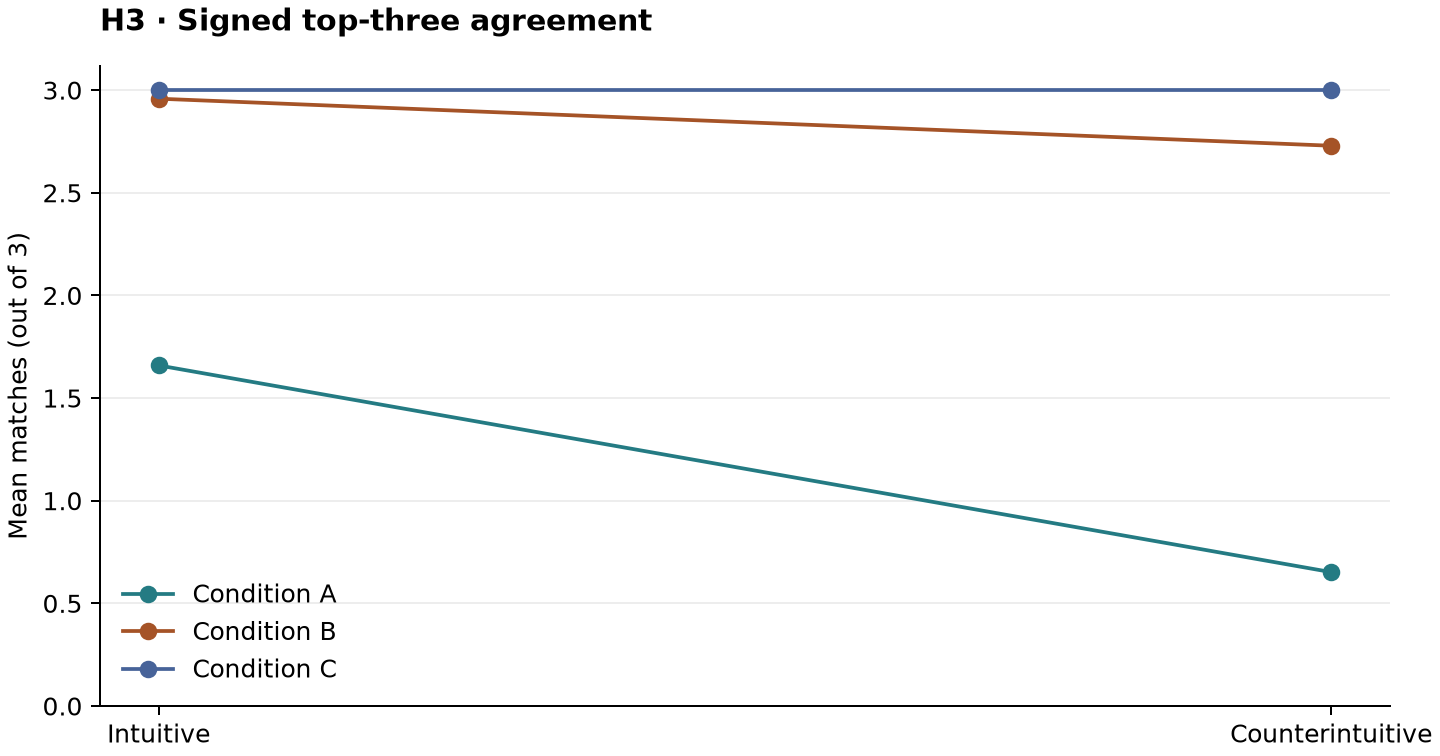

Experiment 3 · experiment3-analysis-v2. Valid/selected outputs by arm and variant (A intuitive 44/48, A counterintuitive 46/48, B intuitive 48/48, B counterintuitive 48/48, C intuitive 48/48, C counterintuitive 48/48). The paired contrast table gives whole-profile 95% intervals. C includes deterministic fallbacks.

In [4]:
if 3 in analyses:
    e3 = analyses[3]
    table(e3["faithfulness"], ["condition", "variant", "total", "valid", SIGNED,
                               "structured_correct", "incorrect_direction_rate",
                               "incorrect_prose_direction_rate", "parser_coverage"])
    table([r for r in e3["paired"] if r["stratum"] == "all" and r["metric"] == SIGNED])
    table([dict(layer=layer, **r) for layer, key in (
        ("Structured", "structured_claim_rates"), ("Structured and prose", "claim_rates"))
        for r in e3[key] if r["outcome"] == "clinical_expectation_substitution" and not r["top_three_only"]])
    table(e3["interventions"])
    figure("04_adversarial_agreement")

## 6. Experiment 4 · Deterministic verifier effectiveness

The primary binary comparison uses 60 mathematically erroneous and 60 faithful, complete examples. Gold-unfaithful is positive. The broader 180-response design adds boundary cases. The all-eligible binary sensitivity includes only responses eligible under that definition. Explicit detection marks a recognized mathematical error. Conservative withholding also responds to grammar coverage, ambiguity, schema validity and completeness.

The targeted live supplement covers previously withheld fictional drafts. A blinded reviewer judged Qwen3's **revisions** independently. The final release composition includes deterministic fallback deliveries. The public summary links the supplement to the frozen challenge and selection, and its schema and totals are checked here.

,group,responses
0,Faithful and complete,60
1,Mathematical corruption,60
2,Boundary challenges,60


,cohort,decision,n,TP,FP,TN,FN
0,primary,explicit,120,52,0,60,8
1,primary,release,120,60,36,24,0
2,all_eligible_sensitivity,explicit,148,56,0,80,12
3,all_eligible_sensitivity,release,148,68,56,24,0


,cohort,decision,metric,numerator,denominator,estimate,ci95_low,ci95_high,clusters
0,primary,explicit,precision,52,52,1.0000,1.0000,1.0000,6
1,primary,explicit,recall,52,60,0.8667,0.8000,0.9333,6
2,primary,explicit,specificity,60,60,1.0000,1.0000,1.0000,6
3,primary,explicit,false_positive_rate,0,60,0.0000,0.0000,0.0000,6
4,primary,release,precision,60,96,0.6250,0.6250,0.6250,6
5,primary,release,recall,60,60,1.0000,1.0000,1.0000,6
6,primary,release,specificity,24,60,0.4000,0.4000,0.4000,6
7,primary,release,false_positive_rate,36,60,0.6000,0.6000,0.6000,6
8,all_eligible_sensitivity,explicit,precision,56,56,1.0000,1.0000,1.0000,6
9,all_eligible_sensitivity,explicit,recall,56,68,0.8235,0.7353,0.9118,6


,faithfulness,completeness,schema,outcome,n
0,faithful,incomplete,valid,ambiguous_or_unparsed,4
1,faithful,incomplete,valid,incomplete_but_otherwise_correct,16
2,faithful,not_applicable,invalid,schema_invalid,24
3,indeterminate,complete,valid,ambiguous_or_unparsed,8
4,unfaithful,complete,valid,ambiguous_or_unparsed,4
5,unfaithful,complete,valid,explicit_error_detected,4


,style,numerator,denominator,estimate,ci95_low,ci95_high,clusters
0,all,36,60,0.6,0.6,0.6,6
1,alias,0,6,0.0,0.0,0.0,6
2,compound,0,6,0.0,0.0,0.0,6
3,direct,0,12,0.0,0.0,0.0,6
4,passive,6,6,1.0,1.0,1.0,6
5,pronoun,6,6,1.0,1.0,1.0,6
6,qualified,6,6,1.0,1.0,1.0,6
7,reference,6,6,1.0,1.0,1.0,6
8,relative,6,6,1.0,1.0,1.0,6
9,shared,6,6,1.0,1.0,1.0,6


,category,numerator,denominator,estimate,ci95_low,ci95_high,clusters
0,incorrect_attribution_ranking,8,8,1.0,1.0000,1.0000,6
1,incorrect_feature_direction,12,20,0.6,0.3333,0.8182,6
2,incorrect_feature_importance,8,8,1.0,1.0000,1.0000,6
3,incorrect_probability,4,4,1.0,1.0000,1.0000,4
4,incorrect_shap_scale,4,4,1.0,1.0000,1.0000,4
5,invented_measurement,4,4,1.0,1.0000,1.0000,4
6,structured_prose_contradiction,8,20,0.4,0.2222,0.5455,6
7,unsupported_causal_claim,4,4,1.0,1.0000,1.0000,4
8,unsupported_clinical_diagnosis,4,4,1.0,1.0000,1.0000,4
9,unsupported_model_feature,4,4,1.0,1.0000,1.0000,4


,layer,numerator,denominator,estimate,ci95_low,ci95_high,clusters
0,structured,16,16,1.00,1.0000,1.0000,6
1,narrative,36,48,0.75,0.6667,0.8333,6


,attempted,requests,valid_revisions,original_accepted,original_correctly_rejected,original_falsely_rejected,accepted_revisions,failed_revisions,fallback,pending_gold,...,full_genuine_corrections,false_rejection_repairs,accepted_unfaithful,rejected_faithful_revision,new_errors,final_faithful,final_complete,rates,latency_seconds,median_latency_seconds
0,11,10,8,1,9,1,3,7,7,0,...,1,1,0,1,1,11,10,"{'model_revision_success': {'numerator': 1, 'd...",0.0002,0.0


,outcome,numerator,denominator,rate
0,Faithful revisions,28,30,NaN
1,Verifier-accepted revisions,16,30,NaN
2,Deterministic fallbacks,14,30,NaN
3,"Faithful, complete, valid revisions withheld",12,28,0.4286
4,Unfaithful revisions rejected,2,2,NaN


1 blinded human reviewer. Selected samples provide descriptive rates.


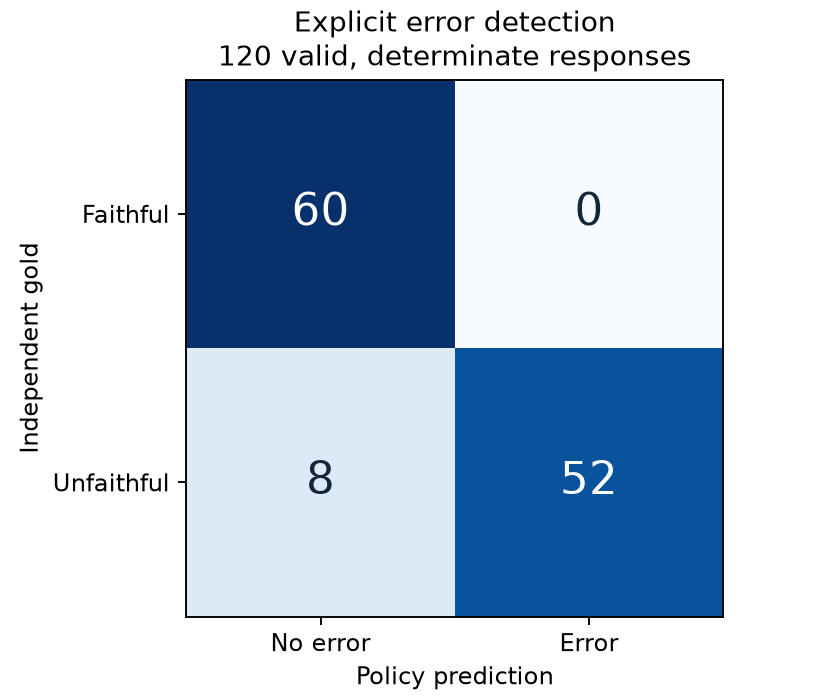

Experiment 4 · experiment4-analysis-v1. Primary comparison of 120 fictional responses. A positive is a mathematical error. Only explicitly detected errors count as flags.

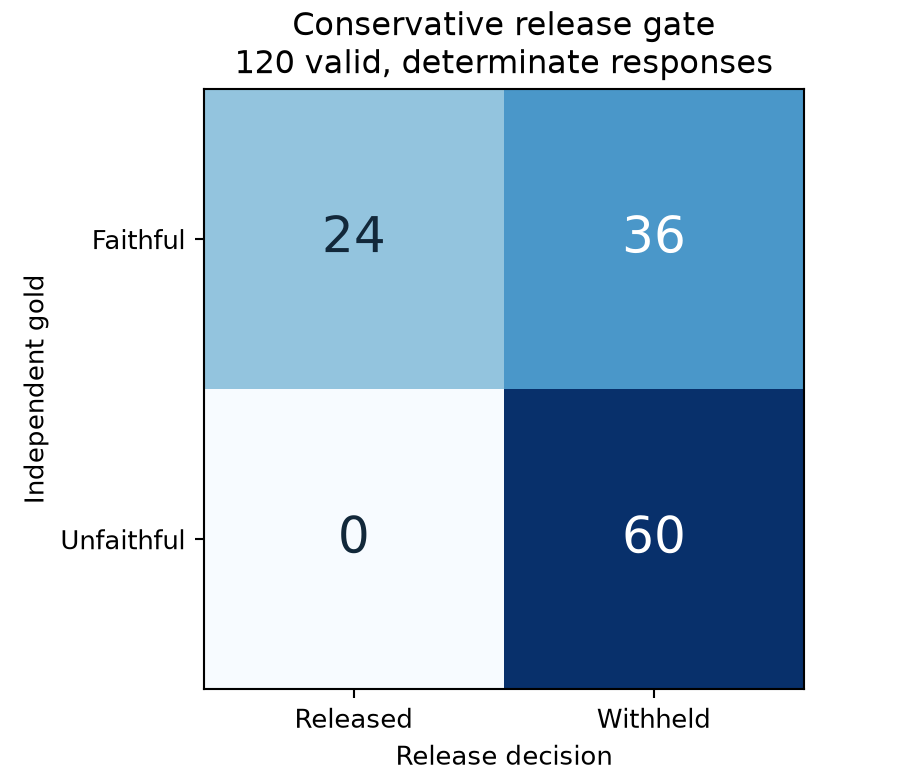

Experiment 4 · experiment4-analysis-v1. The same 120 fictional responses. Withholding includes ambiguity and incompleteness. The metrics table reports profile-cluster intervals for both policies.

In [5]:
if 4 in analyses:
    e4 = analyses[4]
    table([dict(group=label, responses=e4["composition"][group]) for group, label in (
        ("A", "Faithful and complete"), ("B", "Mathematical corruption"), ("C", "Boundary challenges"))])
    table(verifier_rows(e4))
    table([r for r in verifier_metrics(e4) if r["metric"] in
           {"precision", "recall", "specificity", "false_positive_rate"}])
    table(e4["boundary"])
    table([dict(style=r["style"], **r["false_rejection"]) for r in e4["false_rejection"]])
    table([dict(category=r["category"], **r["explicitly_detected"]) for r in e4["error_matrix"]])
    table([dict(layer=key, **e4["layers"][key]["metrics"]["recall"]) for key in ("structured", "narrative")])
    table([e4["scripted_corrections"]])
    live = e4["live"]
    n = live["overall"]["selected_drafts"]
    table([dict(outcome=label, numerator=live["overall"][key], denominator=n)
           for label, key in (("Faithful revisions", "faithful"), ("Verifier-accepted revisions", "accepted"),
                              ("Deterministic fallbacks", "fallback"))] + [
        dict(outcome="Faithful, complete, valid revisions withheld",
             **live["rates"]["false_rejection_faithful_complete_valid"]),
        dict(outcome="Unfaithful revisions rejected", numerator=live["classification_counts"]["correct_rejection"],
             denominator=live["overall"]["unfaithful"])])
    print(f'{live["reviewers"]} blinded human reviewer. Selected samples provide descriptive rates.')
    figure("05a_explicit_detection")
    figure("05b_release_rejection", figure_bytes(release_figure(e4)))

## 7. Experiment 5 · Human explanation evaluation

The same reviewer rated clarity and readability before seeing the reference, then judged mathematical faithfulness and completeness. Faithfulness among determinate judgments uses faithful plus unfaithful labels. The all-selected measure retains indeterminate and invalid records in the denominator. Each paired analysis uses admissions with an eligible rating in both conditions for that endpoint. Completeness change uses insufficient, partial and complete in ascending order.

The C delivery comparison is descriptive. The gate influences which drafts, revisions and fallbacks appear in each group. A zero-size group has no ratings. A small group mean is sensitive to individual scores.

72 locked primary ratings, 24 admissions, 1 reviewer.


,condition,selected,faithful,unfaithful,indeterminate,invalid,determinate,determinate_rate,all_selected_rate,determinate_ci95,insufficient,partial,complete,not_applicable,clarity_mean,clarity_median,readability_mean,readability_median
0,A,24,12,11,1,0,23,0.5217,0.5000,"[0.3181818181818182, 0.7272727272727273]",0,21,3,0,5.0000,5.0,5.0000,5.0
1,B,24,23,1,0,0,24,0.9583,0.9583,"[0.875, 1.0]",0,3,21,0,4.7917,5.0,4.7917,5.0
2,C,24,24,0,0,0,24,1.0000,1.0000,"[1.0, 1.0]",0,0,24,0,3.6250,4.0,3.2500,3.0


,condition,outcome,rated,1,2,3,4,5
0,A,clarity_1_to_5,24,0,0,0,0,24
1,A,readability_1_to_5,24,0,0,0,0,24
2,B,clarity_1_to_5,24,0,0,0,5,19
3,B,readability_1_to_5,24,0,0,2,1,21
4,C,clarity_1_to_5,24,0,0,10,13,1
5,C,readability_1_to_5,24,0,0,19,4,1


,comparison,metric,matched_n,eligible_n,improved,worsened,unchanged,mean_change,median_change,mean_change_ci95
0,B − A,mathematical_faithfulness,24,23,10,0,13,0.4348,0.0,"[0.22727272727272727, 0.6363636363636364]"
1,B − A,completeness,24,24,18,0,6,0.7500,1.0,"[0.5833333333333334, 0.9166666666666666]"
2,B − A,clarity_1_to_5,24,24,0,5,19,-0.2083,0.0,"[-0.375, -0.041666666666666664]"
3,B − A,readability_1_to_5,24,24,0,3,21,-0.2083,0.0,"[-0.4583333333333333, 0.0]"
4,C − B,mathematical_faithfulness,24,24,1,0,23,0.0417,0.0,"[0.0, 0.125]"
5,C − B,completeness,24,24,3,0,21,0.1250,0.0,"[0.0, 0.2916666666666667]"
6,C − B,clarity_1_to_5,24,24,0,20,4,-1.1667,-1.0,"[-1.4583333333333333, -0.875]"
7,C − B,readability_1_to_5,24,24,0,20,4,-1.5417,-2.0,"[-1.8333333333333333, -1.2083333333333333]"
8,C − A,mathematical_faithfulness,24,23,11,0,12,0.4783,0.0,"[0.2727272727272727, 0.6818181818181818]"
9,C − A,completeness,24,24,21,0,3,0.8750,1.0,"[0.75, 1.0]"


,source,n,faithful,unfaithful,indeterminate,invalid,complete,mean_clarity,mean_readability
0,grounded_draft,0,0,0,0,0,0,NaN,NaN
1,model_revision,3,3,0,0,0,3,4.3333,4.0000
2,deterministic_fallback,21,21,0,0,0,21,3.5238,3.1429


**Intra-reviewer consistency analysis pending.** 0/12 repeat ratings recorded.

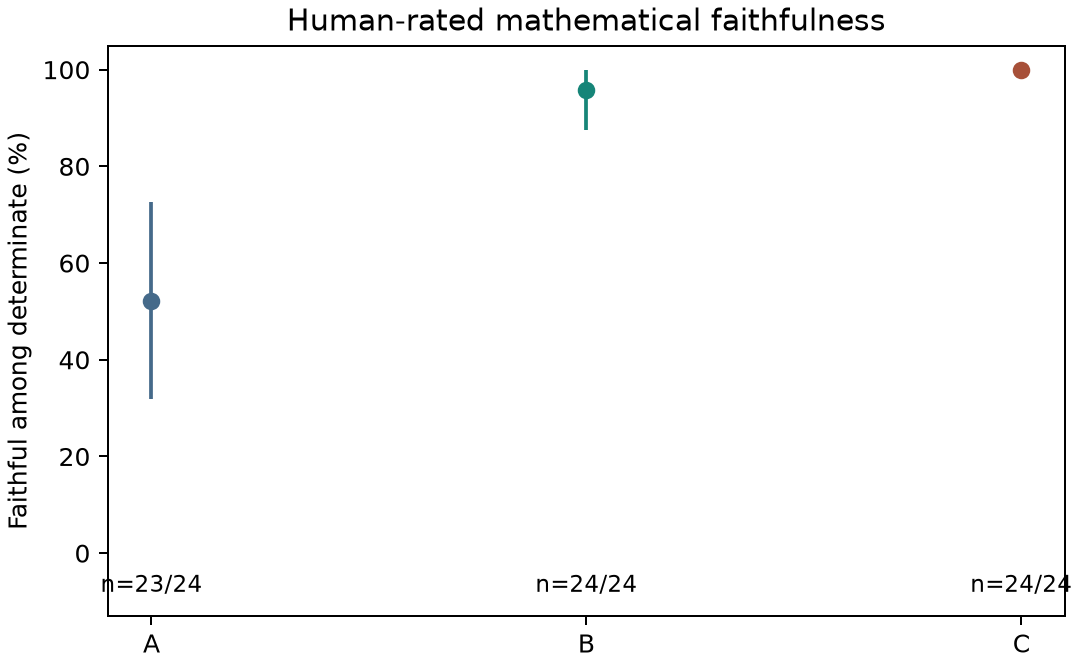

Experiment 5 · experiment5-analysis-v1. One reviewer, 24 selected admissions. Points use determinate judgments and lines are admission-bootstrap 95% intervals.

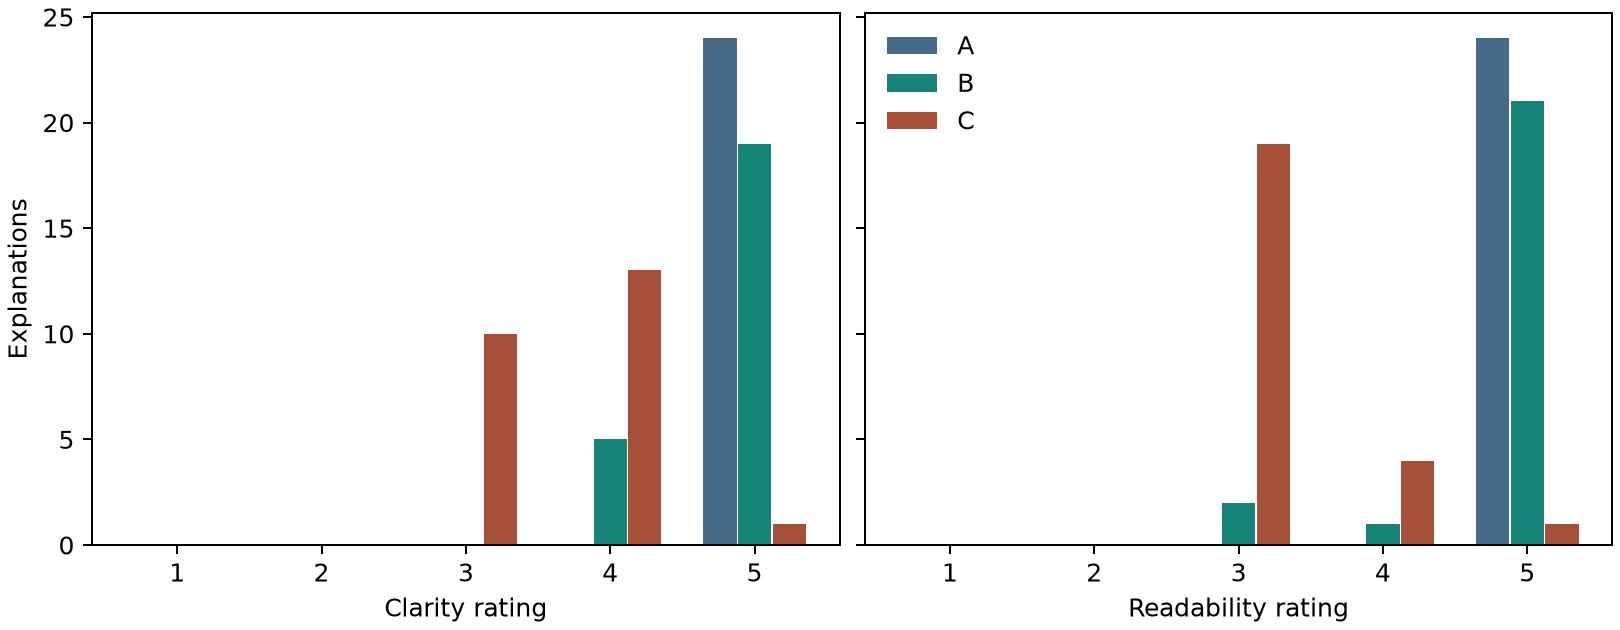

Experiment 5 · experiment5-analysis-v1. Ordinal rating counts, 24 selected per condition. Descriptive distributions. See the paired table for contrasts and intervals.

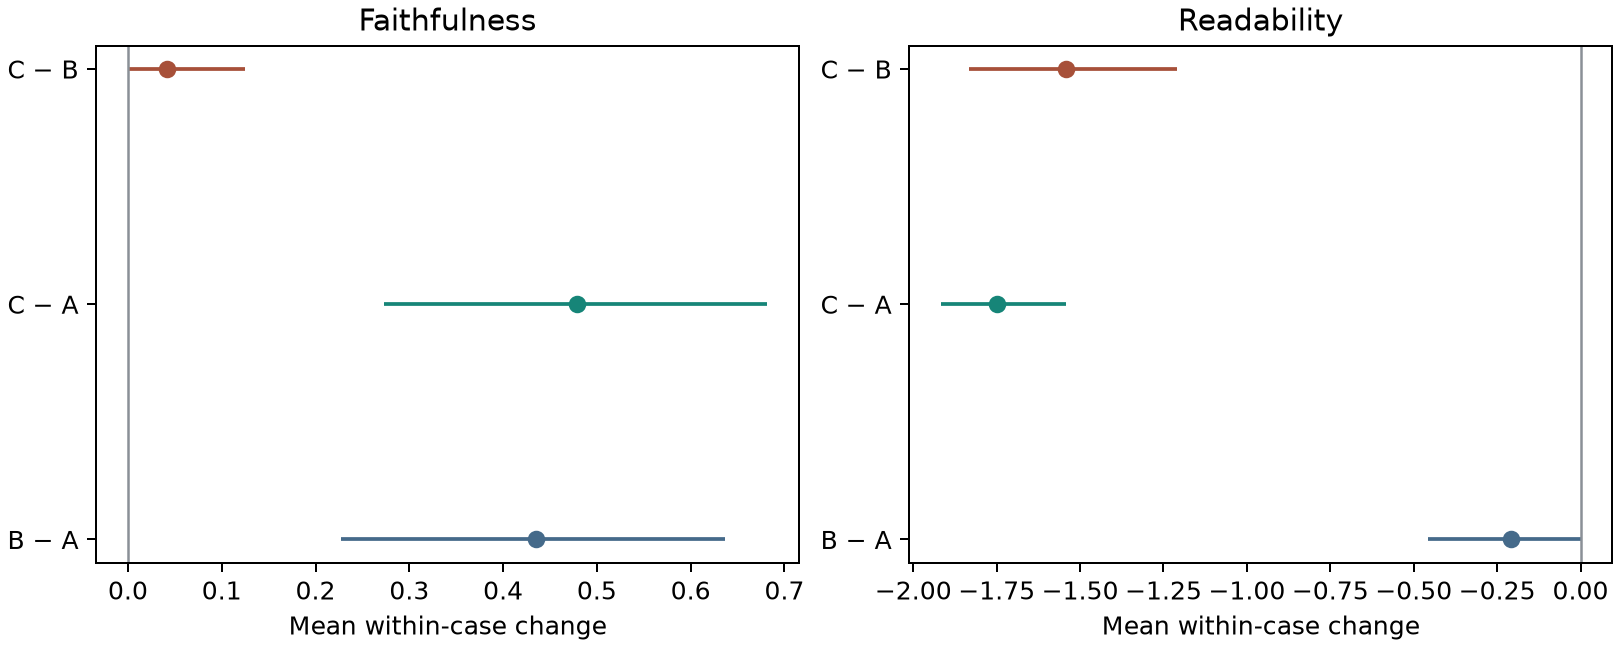

Experiment 5 · experiment5-analysis-v1. Within-admission mean changes for 24 matched admissions. Lines are admission-bootstrap 95% intervals. Eligible counts differ by outcome and appear in the paired table.

In [6]:
if 5 in analyses:
    e5 = analyses[5]
    print(f'{e5["explanations"]} locked primary ratings, {e5["clusters"]} admissions, {e5["reviewers"]} reviewer.')
    table(human_condition_rows(e5))
    table([dict(condition=arm, outcome=field, rated=row[field]["n"],
                **row[field]["distribution"])
           for arm, row in e5["by_condition"].items() for field in (CLEAR, READ)])
    table(human_comparison_rows(e5), ["comparison", "metric", "matched_n", "eligible_n", "improved",
           "worsened", "unchanged", "mean_change", "median_change", "mean_change_ci95"])
    table([dict(source=source, n=row["n"], **row["faithfulness"], complete=row["completeness"]["complete"],
                mean_clarity=row[CLEAR]["mean"], mean_readability=row[READ]["mean"])
           for source, row in e5["condition_c_by_final_source"].items()])
    display(Markdown(f'**{e5["repeat_status"]["status"]}** '
                     f'{e5["repeat_status"]["recorded"]}/{e5["repeat_status"]["selected"]} repeat ratings recorded.'))
    if e5["repeat_consistency"] is not None:
        table([e5["repeat_consistency"]])
    figure("06_local_human_faithfulness")
    figure("07_local_human_text_ratings")
    figure("08_local_human_matched_changes")

## 8. Cross-experiment synthesis

The master table uses the original hypotheses and the source-specific result definitions. “Supported” indicates that the designated evidence follows the hypothesis within the study design. For directional bootstrap contrasts, the interval must exclude zero in the predicted direction. A contrary interval would be classified as unsupported. Mixed endpoints or evidence for only part of a hypothesis are partially supported. H4 is a descriptive challenge comparison. An unavailable or unresolved outcome is inconclusive.

In [7]:
if analyses:
    table(hypothesis_rows(study))

,experiment,hypothesis,research_question,metric,comparison,result,ci95,assessment,interpretation,limitation,evidence
0,1,Model reference,What prediction and attribution reference supp...,Test average precision,Held-out XGBoost vs test prevalence,"0.304 vs 0.112 (n=53,379)","[+0.282, +0.328]",Descriptive,XGBoost was selected on validation.,Prediction discrimination measures a different...,frozen model evaluation v1
1,2,H1,SHAP grounding improves model-feature and dire...,Mean signed top-three matches (0–3),A→B,+1.943 (70 pairs),"[+1.757, +2.129]",Supported,Grounded drafts better match the fitted model'...,Free-form prose coverage was low.,experiment2-analysis-v1
2,2,H2,"Verification, correction and fallback improve ...",Mean signed top-three matches (0–3),B→C,+0.083 (72 pairs); 72/72 verified complete,"[+0.014, +0.181]",Supported,The final system improved signed agreement and...,Model revision and deterministic fallback have...,experiment2-analysis-v1
3,3,H3,Faithfulness may decline when attributions con...,Mean signed top-three matches (0–3),"Counterintuitive − intuitive, by condition",A -1.000 (44 pairs); B -0.229 (48 pairs); C +0...,"A [-1.227, -0.762]; B [-0.479, -0.021]; C [+0....",Partially supported,A and B showed losses in this benchmark. C ret...,The synthetic model switch can also change pro...,experiment3-analysis-v2
4,4,H4,Structured errors are detected more reliably a...,Layer recall and false-positive rate,Structured vs narrative; explicit vs release,Recall 16/16 vs 36/48; false positives 0/60 vs...,"Structured [+1.000, +1.000]; Narrative [+0.667...",Supported,Parser and release behavior diverged on the au...,Layer-specific errors have different denominat...,experiment4-analysis-v1
5,5,H5a,B has higher human-assessed faithfulness than A.,Determinate faithfulness difference,B − A,+0.435 (23/24 pairs),"[+0.227, +0.636]",Supported,The reviewer more often judged grounded drafts...,Single reviewer and a selected sample of compl...,experiment5-analysis-v1
6,5,H5b,Fallback-heavy verified delivery may have lowe...,Readability points (1–5),C − B,-1.542 (24/24 pairs),"[-1.833, -1.208]",Partially supported,Readability declined in C. Delivery source and...,Single reviewer and a selected sample of compl...,experiment5-analysis-v1
7,5,H5c,Faithfulness and readability may move separately.,Faithfulness and readability,"C − A, endpoint-specific matched denominators",Faithfulness +0.478 (n=23); readability -1.750...,"Faithfulness [+0.273, +0.682]; readability [-1...",Supported,The paired condition-level movements were dist...,This comparison does not estimate individual-l...,experiment5-analysis-v1
8,5,H5d,Optional synthetic ratings may find plausible ...,Human faithfulness by variant,Optional secondary study,Outside the primary snapshot,Unavailable,Inconclusive,The primary human study does not address this ...,The synthetic automated benchmark measures a d...,experiment5-analysis-v1


In [8]:
if 2 in analyses and 3 in analyses:
    display(Markdown(
        "### Grounding and clinical intuition\n\n"
        "The H1 and H3 rows show that grounding improved signed driver agreement and reduced the observed "
        "reversal penalty. The grounded draft still lost agreement on the counterintuitive variant. "
        "Clinical intuition can coincide with a model direction while providing no evidence about "
        "how this fitted model produced a prediction."
    ))
if 2 in analyses and 3 in analyses:
    display(Markdown(
        "### Structured and narrative faithfulness\n\n"
        "Experiments 2 and 3 distinguish structured driver accuracy from the paragraph. Low prose-parser "
        "coverage limits the inference from correct structured directions to free-form narrative quality."
    ))
if 4 in analyses:
    display(Markdown(
        "### Detection and conservative withholding\n\n"
        "The release gate withheld mathematical errors that the checker could not explicitly classify. "
        "It also withheld faithful paraphrases. The live supplement shows that separately reviewed Qwen3 "
        "revisions could be faithful and still trigger fallback."
    ))
if 5 in analyses:
    display(Markdown(
        "### Faithfulness and readability\n\n"
        "C’s gain over B in human faithfulness was small and its interval touched zero. The paired "
        "readability interval supported a decline. Relative to A, human-rated faithfulness and "
        "readability moved in opposite directions. Delivery-source summaries describe selected groups "
        "and cannot isolate an effect of repetitive wording."
    ))

### Grounding and clinical intuition

The H1 and H3 rows show that grounding improved signed driver agreement and reduced the observed reversal penalty. The grounded draft still lost agreement on the counterintuitive variant. Clinical intuition can coincide with a model direction while providing no evidence about how this fitted model produced a prediction.

### Structured and narrative faithfulness

Experiments 2 and 3 distinguish structured driver accuracy from the paragraph. Low prose-parser coverage limits the inference from correct structured directions to free-form narrative quality.

### Detection and conservative withholding

The release gate withheld mathematical errors that the checker could not explicitly classify. It also withheld faithful paraphrases. The live supplement shows that separately reviewed Qwen3 revisions could be faithful and still trigger fallback.

### Faithfulness and readability

C’s gain over B in human faithfulness was small and its interval touched zero. The paired readability interval supported a decline. Relative to A, human-rated faithfulness and readability moved in opposite directions. Delivery-source summaries describe selected groups and cannot isolate an effect of repetitive wording.

## 9. Human and automated judgments

Each row uses its own comparable subset. Concordance here is the saved binary denominator minus the two discordant cells. It is a descriptive count. The label counts preserve ambiguous prose and indeterminate or invalid human labels. A clear narrative check can coexist with omitted drivers. The structured check and the final C release decision capture different information.

Controlled false rejection in Experiment 4 provides context for ambiguous or withheld prose. Disagreement in this selected real-case human study can reflect rubric differences, omitted drivers, parser coverage or reviewer error.

In [9]:
if 5 in analyses:
    table(human_verifier_rows(analyses[5]))

,condition,check,concordant,comparable_n,human_faithful_automated_flagged,human_unfaithful_automated_clear,outside_binary,labels
0,A,structured_correct,12,23,11,0,1,"{'indeterminate → False': 1, 'unfaithful → Fal..."
1,A,narrative,0,0,0,0,24,"{'indeterminate → ambiguous': 1, 'unfaithful →..."
2,A,release,0,0,0,0,24,"{'indeterminate → None': 1, 'unfaithful → None..."
3,B,structured_correct,19,24,4,1,0,"{'faithful → True': 19, 'faithful → False': 4,..."
4,B,narrative,0,2,2,0,22,"{'faithful → ambiguous': 21, 'unfaithful → amb..."
5,B,release,0,0,0,0,24,"{'faithful → None': 23, 'unfaithful → None': 1}"
6,C,structured_correct,24,24,0,0,0,{'faithful → True': 24}
7,C,narrative,24,24,0,0,0,{'faithful → no_flag': 24}
8,C,release,24,24,0,0,0,{'faithful → verified_complete': 24}


## 10. Statistical uncertainty and sensitivity

| Experiment | Sampling and frozen uncertainty procedure |
|---|---|
| 1 | Held-out admissions grouped by patient. 300 patient-cluster percentile bootstrap replicates for test AUROC and AP. |
| 2 | 10,000 fixed-seed percentile bootstrap replicates on matched admissions. Complete cases and invalid-output-as-zero sensitivity are reported separately. |
| 3 | 10,000 fixed-seed whole-profile bootstrap replicates on matched fictional variants. The bounded signed agreement also includes a failed-output-zero sensitivity. |
| 4 | 10,000 fixed-seed whole-profile replicates over the authored challenge and profile clusters. Intervals summarize variability across these profiles. The 30 selected live revisions are descriptive. |
| 5 | 10,000 fixed-seed whole-admission bootstrap replicates for determinate faithfulness and endpoint-specific matched contrasts. The all-selected sensitivity retains every selected record. Repeat ratings concern stability within the same reviewer. |

Intervals preserve the original endpoint and pairing. A degenerate interval in an authored or ceiling-limited sample describes the observed resamples. Each sample supports its own uncertainty statement.

## 11. Limitations

- **Prediction.** The source is observational data from one hospital system with a defined cohort and a 30-day observed readmission endpoint. Threshold and calibration behavior may change across institutions, care pathways and populations. Events outside the source system can affect outcome ascertainment.
- **Attribution.** SHAP describes a frozen fitted model relative to its training reference. Grouped feature ranking, ties and negligible contributions follow the frozen conventions. Attribution supplies no estimate of a causal effect.
- **Generation.** One local Qwen3 configuration, finite matched samples and specific prompts constrain generalization. Changes to the prompt or model may change both prose and compliance.
- **Synthetic design.** Authored reversals and challenge categories test a limited set of feature patterns and phrasings. Their frequencies have no direct clinical interpretation.
- **Verification.** Grammar-based checks can withhold valid paraphrases. Structured checks cover claims in the driver list. Constrained deterministic fallback improves the release guarantee within the frozen reference and can change the language the reviewer reads.
- **Human ratings.** One project-familiar reviewer assessed a selected sample. Recognizable style can weaken condition blinding. There is no inter-reviewer estimate. Any repeat analysis addresses only within-reviewer stability.

## 12. Research conclusions

The conclusions below quote primary denominators and paired results from the validated sources when available.

In [10]:
if study.validated and analyses:
    e2, e3, e4, e5 = (analyses[i] for i in (2, 3, 4, 5))
    grounding = paired_grounding(e2, "A→B")
    a, b, c = [paired_reversal(e3, arm) for arm in "ABC"]
    detection, release = (e4["primary"][key]["confusion"] for key in ("explicit", "release"))
    live_counts = e4["live"]["overall"]
    c_read = e5["paired"]["C − B"][READ]
    human_faith = [e5["by_condition"][arm]["faithfulness"]["faithful"] for arm in "ABC"]
    n = e5["clusters"]
    display(Markdown(
        f'1. **Grounding improved mathematical alignment.** Signed driver agreement increased by '
        f'{grounding["mean_difference"]:.2f} of three matches across {grounding["pairs"]} valid admission pairs. '
        f'The fictional reversal penalty was {a["mean_difference"]:.2f} in A and {b["mean_difference"]:.2f} in B.\n'
        f'2. **Release and detection answered different questions.** The verifier explicitly found '
        f'{detection["TP"]}/{detection["TP"] + detection["FN"]} errors. Conservative release withheld '
        f'{release["FP"]}/{release["FP"] + release["TN"]} faithful challenge responses. '
        f'The gate withheld {live_counts["fallback"]}/{live_counts["selected_drafts"]} selected live revisions '
        f'and delivered deterministic fallback for those requests.\n' 
        f'3. **Verified delivery benefited from fallback.** C’s reversal contrast was '
        f'{c["mean_difference"]:.2f} over {c["pairs"]} matched profiles. The C delivery table shows how often '
        f'the system used fallback to obtain that performance.\n'
        f'4. **Faithfulness and readability diverged in the human study.** A/B/C had '
        f'{human_faith[0]}/{n}, {human_faith[1]}/{n} and {human_faith[2]}/{n} faithful ratings among all selected. '
        f'C − B readability was {c_read["mean_change"]:+.2f} points across {c_read["eligible_n"]} admissions '
        f'(95% CI {c_read["mean_change_ci95"][0]:+.2f} to {c_read["mean_change_ci95"][1]:+.2f}). '
        f'The selected sample and one reviewer limit generalization.'
    ))

1. **Grounding improved mathematical alignment.** Signed driver agreement increased by 1.94 of three matches across 70 valid admission pairs. The fictional reversal penalty was -1.00 in A and -0.23 in B.
2. **Release and detection answered different questions.** The verifier explicitly found 52/60 errors. Conservative release withheld 36/60 faithful challenge responses. The gate withheld 14/30 selected live revisions and delivered deterministic fallback for those requests.
3. **Verified delivery benefited from fallback.** C’s reversal contrast was 0.00 over 48 matched profiles. The C delivery table shows how often the system used fallback to obtain that performance.
4. **Faithfulness and readability diverged in the human study.** A/B/C had 12/24, 23/24 and 24/24 faithful ratings among all selected. C − B readability was -1.54 points across 24 admissions (95% CI -1.83 to -1.21). The selected sample and one reviewer limit generalization.

## 13. Report and presentation assets

The versioned export contains the study design, model performance, condition comparisons, verifier confusion matrices, coarsened human outcomes and the master hypothesis-results table. Its figure captions identify the analysis version and denominator. Exact human ratings, linked small cells and the corresponding figures above are for local review. The bundle contains a source manifest and an output checksum index.

A later repeat snapshot can be selected with `HUMAN_VERSION` when available. Select a new synthesis export version to preserve the original bundle.

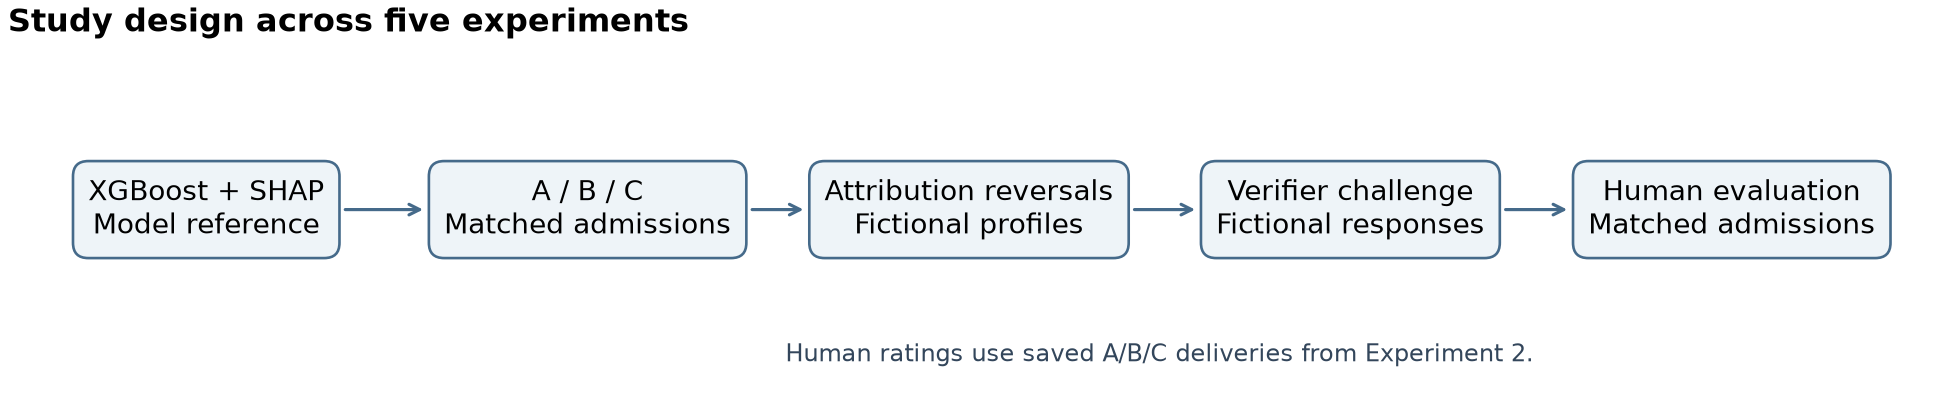

results-synthesis-v1. The study reuses frozen reference artifacts and deliveries across experiments.

In [11]:
if analyses:
    figure("00_pipeline", figure_bytes(pipeline_figure()))
if MODE == "export":
    print(f"Versioned report assets are in results_synthesis/{EXPORT_VERSION}/.")